# Lab 2 · Part I: Neural Networks and Regression

We fit fully connected networks (MLPs) to **(a)** a synthetic 1-D polynomial and **(b)** a real UCI regression
dataset (Concrete Compressive Strength), and study how depth, width, activation function, weight decay and
target complexity affect the fit.

Since this is regression, "accuracy" is reported as **MSE** (the training loss) and **R²** on the train and test sets.
Everything runs on the CPU in a few minutes; seeds are fixed so the numbers are reproducible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

torch.manual_seed(0)
torch.set_num_threads(4)  # tiny models: CPU beats GPU/MPS here
pd.options.display.float_format = "{:.4g}".format
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Polynomial toy dataset

`polynomial(x, coeffs)` evaluates an order-$p$ polynomial with Horner's rule. To make "higher order" also mean
"more complex" (a random-coefficient $x^9$ looks almost flat on $[-1, 1]$), `make_poly` places the $p$ real roots
at randomly jittered Chebyshev nodes, so an order-$p$ polynomial oscillates with full amplitude across the whole
domain ($p-1$ turning points, close to the Chebyshev polynomial $T_p$). It is scaled so that
$\max_{[-1,1]}|f| = 1$, which keeps MSEs comparable across $p$.

Dataset: 1,000 points $x \sim U(-1, 1)$, $y = f(x) + \varepsilon$ with $\varepsilon \sim \mathcal N(0, 0.02^2)$,
split 80/20 into train/test. The noise variance $0.02^2 = 4\cdot10^{-4}$ is the lowest test MSE we can expect.

coefficients (x^3 ... x^0): [ 2.355 -0.308 -1.55   0.113]
train: (800, 1)  test: (200, 1)
MSE of the true f (pure noise): train 4.02e-04, test 4.96e-04


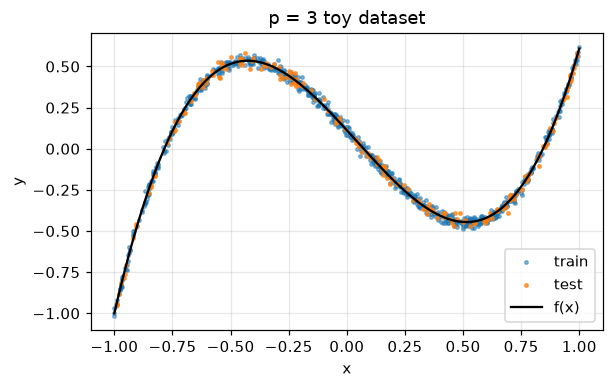

In [2]:
def polynomial(x, coeffs):
    # sum_k c_k x^(p-k), coefficients highest degree first
    y = np.zeros_like(x, dtype=float)
    for c in coeffs:
        y = y * x + c
    return y

def make_poly(p, seed=0):
    rng = np.random.default_rng(seed)
    k = np.arange(1, p + 1)
    roots = np.cos((2 * k - 1 + rng.uniform(-0.3, 0.3, p)) * np.pi / (2 * p))
    coeffs = np.poly(roots)
    return coeffs / np.abs(polynomial(np.linspace(-1, 1, 2001), coeffs)).max()

NOISE = 0.02

def to_tensor(a):
    a = torch.tensor(np.asarray(a), dtype=torch.float32)
    return a.unsqueeze(1) if a.ndim == 1 else a

def make_dataset(p, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    coeffs = make_poly(p, seed)
    x = rng.uniform(-1, 1, n)
    y = polynomial(x, coeffs) + NOISE * rng.standard_normal(n)
    x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.2, random_state=seed)
    return coeffs, tuple(map(to_tensor, (x_tr, y_tr, x_te, y_te)))

coeffs, data = make_dataset(p=3)
X_tr, y_tr, X_te, y_te = data
print("coefficients (x^3 ... x^0):", np.round(coeffs, 3))
print("train:", tuple(X_tr.shape), " test:", tuple(X_te.shape))
f_mse = lambda X, y: np.mean((polynomial(X[:, 0].numpy(), coeffs) - y[:, 0].numpy()) ** 2)
print(f"MSE of the true f (pure noise): train {f_mse(X_tr, y_tr):.2e}, test {f_mse(X_te, y_te):.2e}")

grid = np.linspace(-1, 1, 400)
plt.figure(figsize=(6, 3.5))
plt.scatter(X_tr, y_tr, s=5, alpha=0.5, label="train")
plt.scatter(X_te, y_te, s=5, alpha=0.7, label="test")
plt.plot(grid, polynomial(grid, coeffs), "k", lw=1.5, label="f(x)")
plt.xlabel("x"); plt.ylabel("y"); plt.title("p = 3 toy dataset"); plt.legend()
plt.show()

## 2. Feedforward network at initialization

A generic MLP: `Linear` layers of width $m$ with an activation in between, and a linear output. The baseline is
2 hidden layers of width $m = 64$ with ReLU, using PyTorch's default (Kaiming-uniform) random initialization.

MLP(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
parameters: 4353


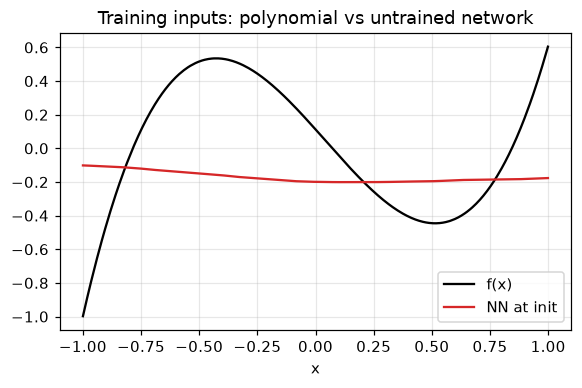

initial train MSE: 0.1649


In [3]:
class MLP(nn.Module):
    def __init__(self, in_dim=1, hidden=(64, 64), act=nn.ReLU):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), act()]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def n_params(model):
    return sum(p.numel() for p in model.parameters())

torch.manual_seed(0)
model = MLP()
print(model)
print("parameters:", n_params(model))

order = X_tr[:, 0].argsort()
with torch.no_grad():
    y_init = model(X_tr)
plt.figure(figsize=(6, 3.5))
plt.plot(X_tr[order], polynomial(X_tr[order, 0].numpy(), coeffs), "k", label="f(x)")
plt.plot(X_tr[order], y_init[order], "C3", label="NN at init")
plt.xlabel("x"); plt.title("Training inputs: polynomial vs untrained network"); plt.legend()
plt.show()
print(f"initial train MSE: {F.mse_loss(y_init, y_tr).item():.4f}")

**Observations.** The untrained network is an almost constant, slightly tilted line: with the default
initialization the output of a ReLU net has a small scale and is only a mild piecewise-linear function of $x$.
It has nothing to do with $f$; its MSE is about $\mathrm{Var}(y)$, no better than predicting a constant.

## 3. Training with MSE

**How the gradients are computed.** The forward pass records a computational graph. For a mini-batch $B$,
$L(\theta) = \frac{1}{|B|}\sum_{i\in B}(f_\theta(x_i) - y_i)^2$, and `loss.backward()` runs reverse-mode automatic
differentiation (backpropagation): starting from $\partial L/\partial \hat y_i = \frac{2}{|B|}(\hat y_i - y_i)$, the chain
rule is applied layer by layer from the output back to the input. For a layer $z = W a + b$ followed by
$a' = \sigma(z)$, with $\delta = \partial L/\partial z$:
$\partial L/\partial W = \delta\, a^\top$, $\partial L/\partial b = \delta$, and the error sent to the previous layer is
$W^\top\delta$ multiplied elementwise by $\sigma'$ of that layer's pre-activation (for ReLU, $\sigma'(z) = \mathbb 1[z>0]$).
The gradients are *accumulated* into each parameter's `.grad`, which is why `zero_grad()` is called every step.

**How the weights are updated.** We use mini-batch training (batch size 32, reshuffled every epoch) with **Adam**:
$m \leftarrow \beta_1 m + (1-\beta_1) g$, $v \leftarrow \beta_2 v + (1-\beta_2) g^2$,
$\theta \leftarrow \theta - \eta\,\hat m / (\sqrt{\hat v} + \epsilon)$ ($\hat m, \hat v$ bias-corrected,
$\eta = 10^{-3}$). Plain SGD would be $\theta \leftarrow \theta - \eta g$. With weight decay $\lambda$, the gradient
becomes $g + \lambda\theta$ (the gradient of $\frac\lambda2\|\theta\|^2$).

Quick check that autograd matches the formula for the output layer, and that one SGD step is $\theta - \eta g$:

In [4]:
torch.manual_seed(0)
net = MLP()
xb, yb = X_tr[:32], y_tr[:32]
hidden = net.net[:-1](xb)                         # activations entering the output layer
loss = F.mse_loss(net(xb), yb)
loss.backward()
delta = 2 / len(xb) * (net(xb) - yb)              # dL/dy_hat
print("dL/dW_out matches autograd:", torch.allclose(delta.T @ hidden, net.net[-1].weight.grad, atol=1e-6))

w_old = net.net[-1].weight.detach().clone()
torch.optim.SGD(net.parameters(), lr=0.1).step()
print("SGD step = w - lr * grad:  ", torch.allclose(net.net[-1].weight, w_old - 0.1 * net.net[-1].weight.grad))

dL/dW_out matches autograd: True


SGD step = w - lr * grad:   True


The training loop logs train/test MSE and R² after **every** epoch (below we print a subset and plot all of them).

epoch   1 | train MSE 1.06e-01  R2 0.2378 | test MSE 1.24e-01  R2 0.1734
epoch   2 | train MSE 8.17e-02  R2 0.4102 | test MSE 9.68e-02  R2 0.3569
epoch   3 | train MSE 5.76e-02  R2 0.5842 | test MSE 6.79e-02  R2 0.5491
epoch   4 | train MSE 3.28e-02  R2 0.7631 | test MSE 3.98e-02  R2 0.7354
epoch   5 | train MSE 1.57e-02  R2 0.8866 | test MSE 2.12e-02  R2 0.8594
epoch  20 | train MSE 8.75e-04  R2 0.9937 | test MSE 1.18e-03  R2 0.9922


epoch  40 | train MSE 5.12e-04  R2 0.9963 | test MSE 6.30e-04  R2 0.9958
epoch  60 | train MSE 4.45e-04  R2 0.9968 | test MSE 5.98e-04  R2 0.9960


epoch  80 | train MSE 6.76e-04  R2 0.9951 | test MSE 8.81e-04  R2 0.9942
epoch 100 | train MSE 7.02e-04  R2 0.9949 | test MSE 7.52e-04  R2 0.9950


epoch 120 | train MSE 4.72e-04  R2 0.9966 | test MSE 6.29e-04  R2 0.9958
epoch 140 | train MSE 3.98e-04  R2 0.9971 | test MSE 5.21e-04  R2 0.9965


epoch 160 | train MSE 4.02e-04  R2 0.9971 | test MSE 5.27e-04  R2 0.9965
epoch 180 | train MSE 4.40e-04  R2 0.9968 | test MSE 5.89e-04  R2 0.9961


epoch 200 | train MSE 4.90e-04  R2 0.9965 | test MSE 6.43e-04  R2 0.9957


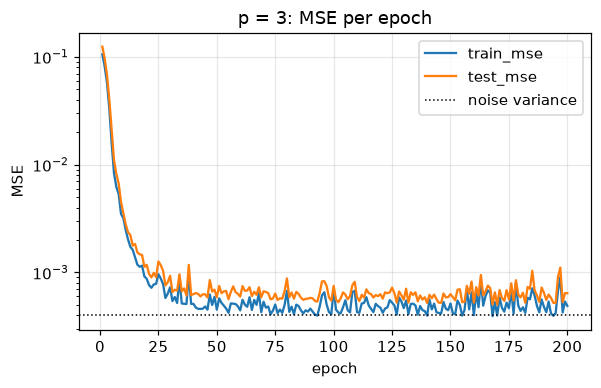

In [5]:
def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        mse = F.mse_loss(model(X), y).item()
    return mse, 1 - mse / y.var(unbiased=False).item()

def train(model, data, epochs=200, lr=1e-3, batch_size=32, weight_decay=0.0, verbose=False):
    X_tr, y_tr, X_te, y_te = data
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = []
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X_tr))
        for i in range(0, len(X_tr), batch_size):
            idx = perm[i:i + batch_size]
            loss = F.mse_loss(model(X_tr[idx]), y_tr[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
        hist.append((epoch, *evaluate(model, X_tr, y_tr), *evaluate(model, X_te, y_te)))
        if verbose and (epoch <= 5 or epoch % 20 == 0):
            e, trm, trr, tem, ter = hist[-1]
            print(f"epoch {e:3d} | train MSE {trm:.2e}  R2 {trr:.4f} | test MSE {tem:.2e}  R2 {ter:.4f}")
    return pd.DataFrame(hist, columns=["epoch", "train_mse", "train_r2", "test_mse", "test_r2"]).set_index("epoch")

def plot_curves(hist, title, noise_floor=None):
    ax = hist[["train_mse", "test_mse"]].plot(logy=True, figsize=(6, 3.5), title=title)
    if noise_floor:
        ax.axhline(noise_floor, color="k", ls=":", lw=1, label="noise variance")
    ax.set_ylabel("MSE"); ax.legend()
    plt.show()

torch.manual_seed(0)
model = MLP()
hist = train(model, data, verbose=True)
plot_curves(hist, "p = 3: MSE per epoch", noise_floor=NOISE**2)

After training, on the **test** inputs, plus a look outside the training range $[-1, 1]$:

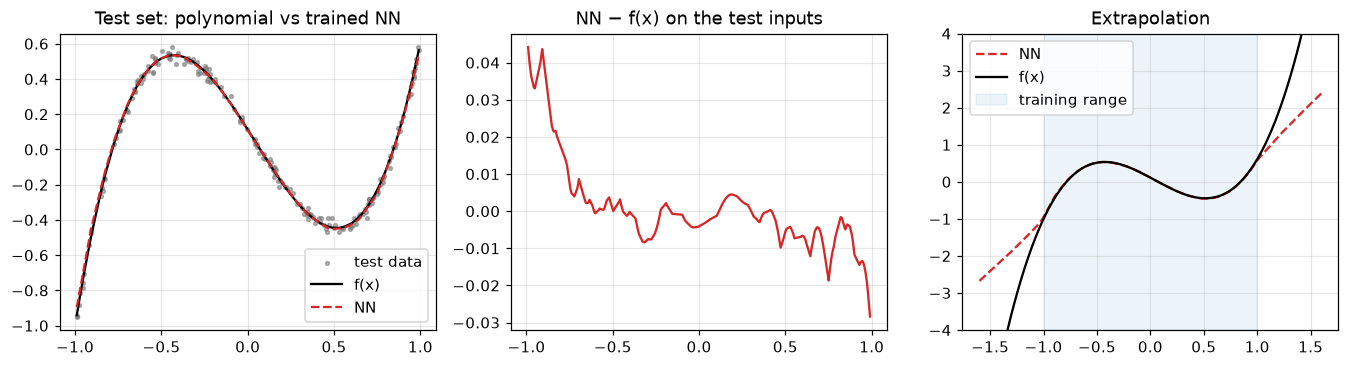

In [6]:
order = X_te[:, 0].argsort()
with torch.no_grad():
    y_hat = model(X_te)[order, 0]
x_sorted = X_te[order, 0].numpy()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].scatter(x_sorted, y_te[order, 0], s=6, c="gray", alpha=0.6, label="test data")
ax[0].plot(x_sorted, polynomial(x_sorted, coeffs), "k", label="f(x)")
ax[0].plot(x_sorted, y_hat, "C3--", label="NN")
ax[0].set_title("Test set: polynomial vs trained NN"); ax[0].legend()
ax[1].plot(x_sorted, y_hat.numpy() - polynomial(x_sorted, coeffs), "C3")
ax[1].set_title("NN − f(x) on the test inputs")
wide = np.linspace(-1.6, 1.6, 400)
with torch.no_grad():
    ax[2].plot(wide, model(to_tensor(wide))[:, 0], "C3--", label="NN")
ax[2].plot(wide, polynomial(wide, coeffs), "k", label="f(x)")
ax[2].axvspan(-1, 1, color="C0", alpha=0.08, label="training range")
ax[2].set_ylim(-4, 4); ax[2].set_title("Extrapolation"); ax[2].legend()
plt.show()

**Observations.**
- Training converges within ~40 epochs to train MSE ≈ $4.5\cdot10^{-4}$ and test R² ≈ 0.996. The two curves track
  each other, and the true $f$ itself scores $4.0\cdot10^{-4}$ (train) and $5.0\cdot10^{-4}$ (test) because of the noise.
  So the network sits at the noise level, and the small train/test gap comes from the particular test-noise draws, not from overfitting.
- The jitter in the curves comes from mini-batch Adam with a constant learning rate; a decaying learning rate
  would smooth it out.
- The residual is largest at the edges $x \to \pm1$, where $f$ is steepest and the data only constrain the fit from one side.
- Outside the training range the ReLU network is piecewise linear, so it continues as a straight line while the
  cubic grows like $x^3$. The network only learns $f$ where it has seen data.

### Should we use ℓ2 regularization (weight decay)?

Weight decay penalizes large weights to reduce variance (overfitting), at the price of extra bias. Whether it
pays off depends on whether the model overfits, so we try a few values of $\lambda$ (3 seeds each):

In [7]:
def sweep(configs, data, seeds=(0, 1, 2), **train_kw):
    # configs: {name: MLP kwargs (+ optional weight_decay)} -> final metrics, mean over seeds; also the last model
    rows, models = [], {}
    for name, cfg in configs.items():
        cfg = dict(cfg)
        wd = cfg.pop("weight_decay", 0.0)
        finals = []
        for s in seeds:
            torch.manual_seed(s)
            m = MLP(data[0].shape[1], **cfg)
            finals.append(train(m, data, weight_decay=wd, **train_kw).iloc[-1])
        finals = pd.DataFrame(finals)
        models[name] = m
        rows.append({"config": name, "params": n_params(m),
                     "train_mse": finals.train_mse.mean(), "test_mse": finals.test_mse.mean(),
                     "test_mse_std": finals.test_mse.std(), "test_r2": finals.test_r2.mean()})
    return pd.DataFrame(rows).set_index("config"), models

wd_table, _ = sweep({f"λ={wd:g}": dict(weight_decay=wd) for wd in [0, 1e-4, 1e-3, 1e-2, 1e-1]}, data)
wd_table

,params,train_mse,test_mse,test_mse_std,test_r2
config,,,,,
λ=0,4353,0.0004811,0.0006309,2.468e-05,0.9958
λ=0.0001,4353,0.0005103,0.0006596,7.164e-05,0.9956
λ=0.001,4353,0.001219,0.001465,0.0002451,0.9903
λ=0.01,4353,0.01186,0.0159,0.001154,0.8944
λ=0.1,4353,0.1385,0.1516,0.000118,-0.006451


**Observations / answer: no, not for this problem.** Without weight decay, the train error is already at the noise level
and the train/test gap is just noise, so there is no variance left to remove. $\lambda = 10^{-4}$ changes nothing, and
larger values only add bias: at $\lambda = 10^{-2}$ the fit is already clearly biased (R² 0.89). At $\lambda = 10^{-1}$ the
penalty dominates the loss and the network collapses to the mean (R² ≈ 0). Weight decay pays off when the model can
fit the noise: few or noisy samples, high-dimensional inputs, or many parameters relative to the data
(see the Concrete data below). Its strength should then be tuned on validation data. (With Adam, the decoupled
version `AdamW` is usually preferred, since the coupled penalty gets rescaled by the adaptive step size.)

## 4. Architecture and polynomial order

Unless stated otherwise: 2 hidden layers × 64, ReLU, Adam (lr $10^{-3}$), 200 epochs, no weight decay, mean of 3 seeds.

**Number of hidden layers** (width 64):

In [8]:
depth_table, _ = sweep({f"{d} hidden": dict(hidden=(64,) * d) for d in [1, 2, 3, 4]}, data)
depth_table

,params,train_mse,test_mse,test_mse_std,test_r2
config,,,,,
1 hidden,193,0.0004856,0.0006375,2.808e-05,0.9958
2 hidden,4353,0.0004811,0.0006309,2.468e-05,0.9958
3 hidden,8513,0.0004676,0.0005963,4.149e-05,0.996
4 hidden,12673,0.0005572,0.0007407,9.151e-05,0.9951


**Activation function:**

In [9]:
acts = {"ReLU": nn.ReLU, "LeakyReLU": nn.LeakyReLU, "GELU": nn.GELU, "Tanh": nn.Tanh, "Sigmoid": nn.Sigmoid}
act_table, act_models = sweep({k: dict(act=a) for k, a in acts.items()}, data)
act_table

,params,train_mse,test_mse,test_mse_std,test_r2
config,,,,,
ReLU,4353,0.0004811,0.0006309,2.468e-05,0.9958
LeakyReLU,4353,0.0004912,0.0006238,3.931e-05,0.9959
GELU,4353,0.0004594,0.0005645,3.58e-06,0.9963
Tanh,4353,0.0004475,0.0005803,1.988e-05,0.9961
Sigmoid,4353,0.005403,0.006766,0.001779,0.9551


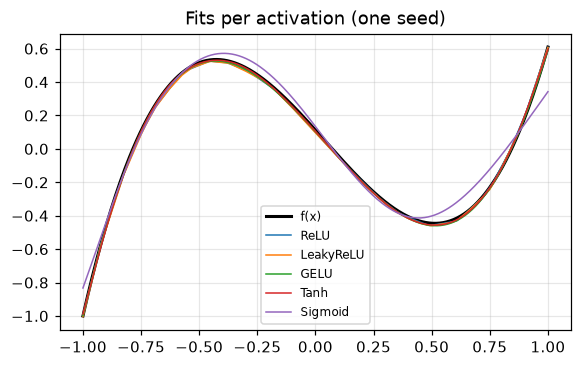

In [10]:
grid_t = to_tensor(grid)
plt.figure(figsize=(6, 3.5))
plt.plot(grid, polynomial(grid, coeffs), "k", lw=2, label="f(x)")
for name, m in act_models.items():
    with torch.no_grad():
        plt.plot(grid, m(grid_t)[:, 0], lw=1, label=name)
plt.title("Fits per activation (one seed)"); plt.legend(fontsize=8)
plt.show()

**Number of parameters** (2 hidden layers, varying width $m$):

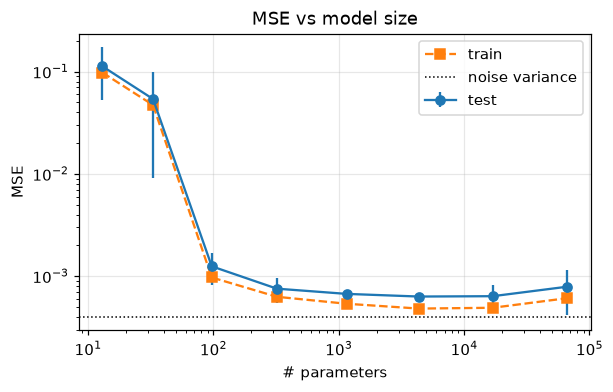

,params,train_mse,test_mse,test_mse_std,test_r2
config,,,,,
m=2,13,0.09794,0.1127,0.06024,0.2516
m=4,33,0.04706,0.05392,0.04473,0.6419
m=8,97,0.0009695,0.001246,0.0004292,0.9917
m=16,321,0.0006272,0.0007531,0.0002087,0.995
m=32,1153,0.0005363,0.0006698,5.438e-05,0.9956
m=64,4353,0.0004811,0.0006309,2.468e-05,0.9958
m=128,16897,0.00049,0.0006358,0.0001807,0.9958
m=256,66561,0.0006083,0.0007874,0.0003723,0.9948


In [11]:
width_table, _ = sweep({f"m={w}": dict(hidden=(w, w)) for w in [2, 4, 8, 16, 32, 64, 128, 256]}, data)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(width_table.params, width_table.test_mse, yerr=width_table.test_mse_std, marker="o", label="test")
ax.plot(width_table.params, width_table.train_mse, "s--", label="train")
ax.axhline(NOISE**2, color="k", ls=":", lw=1, label="noise variance")
ax.set(xscale="log", yscale="log", xlabel="# parameters", ylabel="MSE", title="MSE vs model size")
ax.legend(); plt.show()
width_table

**Observations (p = 3).**
- **Depth:** 1 to 4 hidden layers all reach the noise level; the differences are within the seed spread. Even one
  hidden layer with 193 parameters is enough for a cubic. The deepest net is slightly worse and less stable with the
  same learning rate and epoch budget.
- **Activation:** ReLU, LeakyReLU, GELU and Tanh are all at the noise level. The smooth ones (GELU, Tanh) are
  marginally better, because the target is smooth and ReLU fits are piecewise linear with small kinks. Sigmoid is
  10× worse and the least stable: it saturates, is not zero-centered, and its derivative is at most 1/4, so the
  gradients shrink in every layer and 200 epochs are not enough.
- **Width / #parameters:** $m = 2, 4$ underfit badly and vary a lot between seeds: too few linear pieces, and dead
  ReLUs can remove most of the capacity. From $m = 8$ (~100 parameters) the error is close to the noise level, and
  beyond $m \approx 64$ there is no further gain. Even with 66k parameters for 800 points the network does **not**
  overfit: with tiny noise, gradient training of an over-parameterized net still ends in a smooth function.

**Polynomial order $p$.** Same dataset recipe for $p \in \{1, 3, 5, 9, 15, 21\}$, comparing the baseline
(2×64) with a deeper and wider net (3×128):

In [12]:
P_VALUES = [1, 3, 5, 9, 15, 21]
nets = {"2x64": dict(hidden=(64, 64)), "3x128": dict(hidden=(128, 128, 128))}
rows, fits = [], {}
for p in P_VALUES:
    c, d = make_dataset(p)
    table, models = sweep(nets, d)
    rows.append(table.assign(p=p).reset_index())
    fits[p] = (c, models)
p_table = pd.concat(rows).pivot(index="p", columns="config", values=["train_mse", "test_mse", "test_r2"])
p_table

train_mse            test_mse           test_r2       
config      2x64     3x128      2x64     3x128    2x64  3x128
p                                                            
1       0.000425 0.0005117 0.0005287 0.0006278  0.9981 0.9977
3      0.0004811 0.0005257 0.0006309 0.0006102  0.9958 0.9959
5      0.0009284 0.0008732  0.001023  0.001095  0.9946 0.9942
9       0.008146  0.003594  0.008113  0.003349  0.9622 0.9844
15       0.02391  0.009353   0.02822  0.009442  0.8445  0.948
21       0.09901   0.01398    0.1143   0.02297  0.3456 0.8684

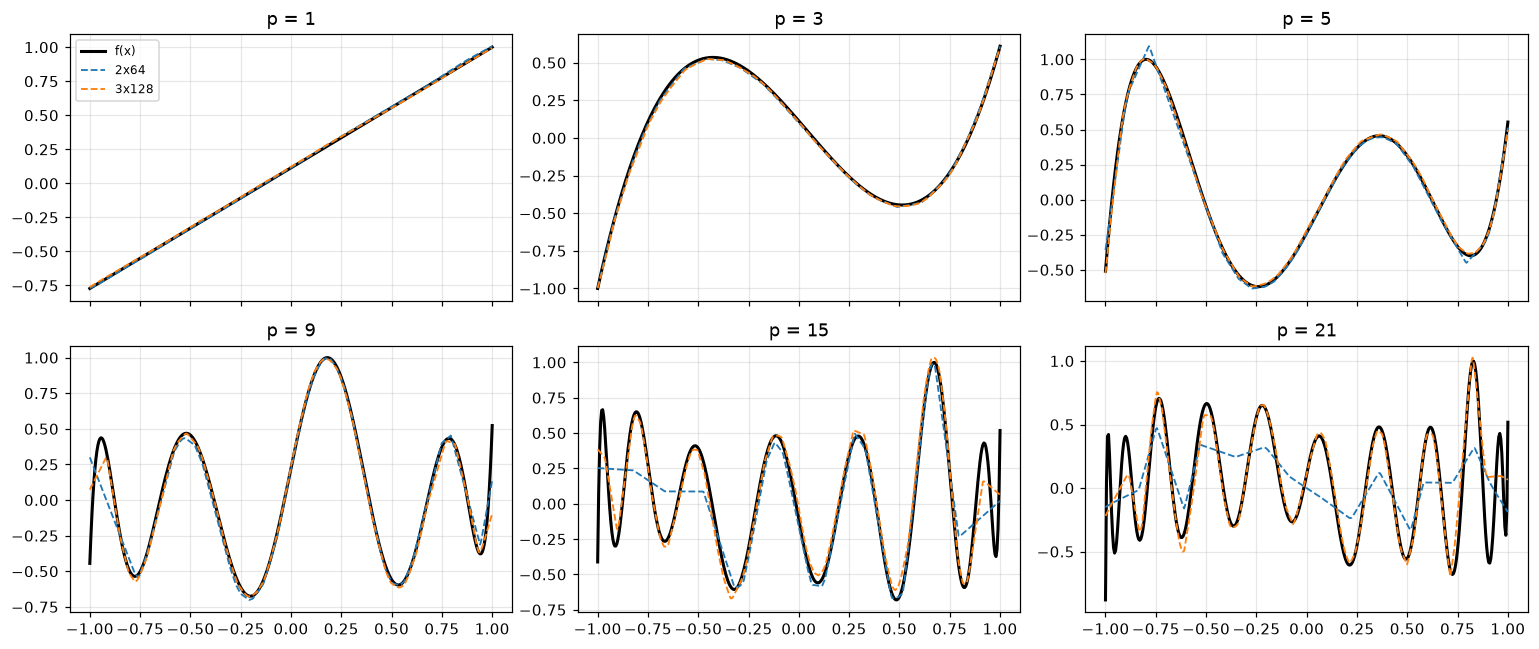

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, p in zip(axes.flat, P_VALUES):
    c, models = fits[p]
    ax.plot(grid, polynomial(grid, c), "k", lw=2, label="f(x)")
    for name, m in models.items():
        with torch.no_grad():
            ax.plot(grid, m(grid_t)[:, 0], "--", lw=1.2, label=name)
    ax.set_title(f"p = {p}")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observations.**
- For low orders ($p \le 5$) both networks reach the noise level. From $p = 9$ the 2×64 net starts to underfit
  (train ≈ test error, so this is bias, not variance), and at $p = 21$ it fails (R² 0.35): it smooths over most of
  the oscillations.
- The deeper and wider 3×128 net is 2-5× better for $p \ge 9$ and still gets R² 0.87 at $p = 21$. A ReLU net needs
  roughly one linear piece per bend of $f$, so the needed capacity grows with $p$. Depth multiplies the number of
  linear regions much faster than width, which makes deeper nets the more efficient way to add capacity here.
- Both nets miss the outermost oscillations first: the Chebyshev roots are densest near $\pm1$, so the local
  frequency is highest there and there is little data on the outer side.
- The NN never sees the coefficients. In the monomial basis they explode with $p$ (on the order of $10^6$ for
  $p = 21$), so fitting a polynomial directly would be badly conditioned, while the difficulty for the NN depends
  only on how wiggly $f$ is.

## 5. Real data: UCI Concrete Compressive Strength

[Concrete Compressive Strength](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength)
(Yeh, 1998): 1,030 concrete mixtures, 8 numeric inputs (amounts of cement, slag, fly ash, water, superplasticizer,
coarse/fine aggregate in kg/m³, and age in days); target is compressive strength in MPa. The relation is known to
be nonlinear (e.g. strength vs. age and water/cement ratio), so it is a good fit for an MLP.

Same 80/20 split; inputs and target are standardized with training-set statistics (the network trains on the
standardized target; we also report RMSE in MPa). An ordinary least-squares model is the reference.

In [14]:
path = Path("data/concrete.csv")
if not path.exists():
    from ucimlrepo import fetch_ucirepo
    uci = fetch_ucirepo(id=165)
    path.parent.mkdir(exist_ok=True)
    pd.concat([uci.data.features, uci.data.targets], axis=1).to_csv(path, index=False)
df = pd.read_csv(path)
X_raw, y_raw = df.iloc[:, :-1].to_numpy(), df.iloc[:, -1].to_numpy()
print(df.shape)
display(df.describe().T[["mean", "std", "min", "max"]])

Xa, Xb, ya, yb = train_test_split(X_raw, y_raw, test_size=0.2, random_state=0)
x_scaler, y_scaler = StandardScaler().fit(Xa), StandardScaler().fit(ya[:, None])
Y_STD = y_scaler.scale_[0]
cdata = (to_tensor(x_scaler.transform(Xa)), to_tensor(y_scaler.transform(ya[:, None])),
         to_tensor(x_scaler.transform(Xb)), to_tensor(y_scaler.transform(yb[:, None])))

def rmse_mpa(mse):  # MSE on the standardized target -> RMSE in MPa
    return np.sqrt(mse) * Y_STD

ols = LinearRegression().fit(cdata[0], cdata[1])
ols_mse = F.mse_loss(torch.tensor(ols.predict(cdata[2]), dtype=torch.float32), cdata[3]).item()
print(f"linear regression: test RMSE {rmse_mpa(ols_mse):.2f} MPa, test R2 {ols.score(cdata[2], cdata[3]):.3f}")

(1030, 9)


,mean,std,min,max
Cement,281.2,104.5,102,540
Blast Furnace Slag,73.9,86.28,0,359.4
Fly Ash,54.19,64,0,200.1
Water,181.6,21.35,121.8,247
Superplasticizer,6.205,5.974,0,32.2
Coarse Aggregate,972.9,77.75,801,1145
Fine Aggregate,773.6,80.18,594,992.6
Age,45.66,63.17,1,365
Concrete compressive strength,35.82,16.71,2.33,82.6


linear regression: test RMSE 9.78 MPa, test R2 0.637


**Step 2 again: the network at initialization.** With 8-D inputs we cannot plot the function, so we plot predicted vs true strength on the training set.

parameters: 4801 | initial train RMSE: 16.8 MPa


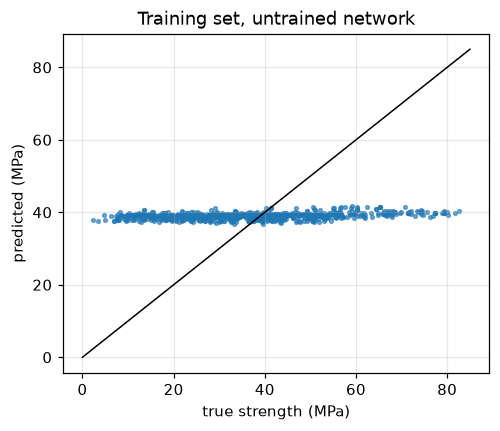

In [15]:
def pred_vs_true(models, X, y, titles):
    fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4), squeeze=False)
    true = y_scaler.inverse_transform(y.numpy())[:, 0]
    for ax, m, title in zip(axes[0], models, titles):
        with torch.no_grad():
            pred = y_scaler.inverse_transform(m(X).numpy())[:, 0]
        ax.scatter(true, pred, s=6, alpha=0.6)
        ax.plot([0, 85], [0, 85], "k", lw=1)
        ax.set(xlabel="true strength (MPa)", ylabel="predicted (MPa)", title=title)
    plt.show()

torch.manual_seed(0)
cmodel = MLP(in_dim=8)
print("parameters:", n_params(cmodel), f"| initial train RMSE: {rmse_mpa(evaluate(cmodel, cdata[0], cdata[1])[0]):.1f} MPa")
pred_vs_true([cmodel], cdata[0], cdata[1], ["Training set, untrained network"])

**Step 3 again: training.** 300 epochs, otherwise the same setup as for the polynomial.

epoch   1 | train MSE 6.58e-01  R2 0.3415 | test MSE 6.28e-01  R2 0.3271
epoch   2 | train MSE 4.17e-01  R2 0.5827 | test MSE 3.78e-01  R2 0.5953
epoch   3 | train MSE 3.39e-01  R2 0.6614 | test MSE 3.17e-01  R2 0.6600
epoch   4 | train MSE 2.81e-01  R2 0.7188 | test MSE 2.63e-01  R2 0.7182
epoch   5 | train MSE 2.33e-01  R2 0.7673 | test MSE 2.29e-01  R2 0.7546
epoch  20 | train MSE 8.86e-02  R2 0.9114 | test MSE 1.27e-01  R2 0.8634


epoch  40 | train MSE 5.38e-02  R2 0.9462 | test MSE 1.17e-01  R2 0.8741
epoch  60 | train MSE 4.42e-02  R2 0.9558 | test MSE 1.11e-01  R2 0.8806


epoch  80 | train MSE 3.57e-02  R2 0.9643 | test MSE 9.98e-02  R2 0.8931
epoch 100 | train MSE 3.57e-02  R2 0.9643 | test MSE 9.85e-02  R2 0.8944


epoch 120 | train MSE 2.78e-02  R2 0.9722 | test MSE 9.63e-02  R2 0.8968
epoch 140 | train MSE 2.74e-02  R2 0.9726 | test MSE 9.51e-02  R2 0.8980


epoch 160 | train MSE 2.37e-02  R2 0.9763 | test MSE 9.57e-02  R2 0.8975
epoch 180 | train MSE 2.36e-02  R2 0.9764 | test MSE 9.51e-02  R2 0.8981


epoch 200 | train MSE 2.44e-02  R2 0.9756 | test MSE 9.08e-02  R2 0.9027
epoch 220 | train MSE 2.05e-02  R2 0.9795 | test MSE 9.07e-02  R2 0.9028


epoch 240 | train MSE 1.78e-02  R2 0.9822 | test MSE 8.70e-02  R2 0.9067
epoch 260 | train MSE 1.82e-02  R2 0.9818 | test MSE 8.85e-02  R2 0.9052


epoch 280 | train MSE 1.91e-02  R2 0.9809 | test MSE 9.07e-02  R2 0.9028
epoch 300 | train MSE 2.02e-02  R2 0.9798 | test MSE 8.68e-02  R2 0.9069

final: train RMSE 2.39 MPa | test RMSE 4.95 MPa, R2 0.907


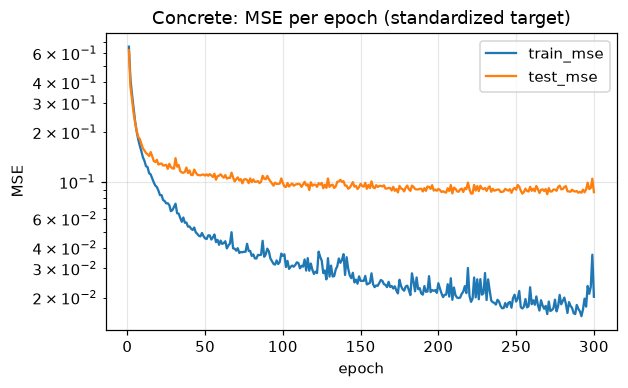

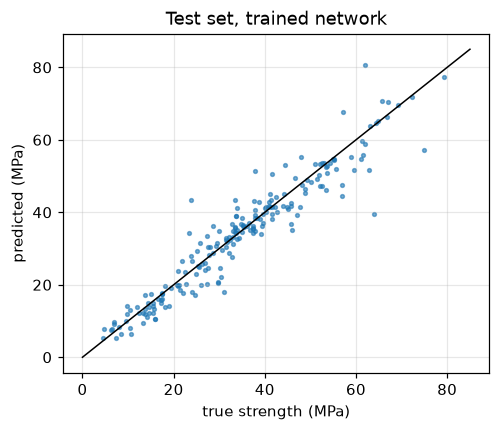

In [16]:
CEPOCHS = 300
chist = train(cmodel, cdata, epochs=CEPOCHS, verbose=True)
final = chist.iloc[-1]
print(f"\nfinal: train RMSE {rmse_mpa(final.train_mse):.2f} MPa | test RMSE {rmse_mpa(final.test_mse):.2f} MPa, R2 {final.test_r2:.3f}")
plot_curves(chist, "Concrete: MSE per epoch (standardized target)")
pred_vs_true([cmodel], cdata[2], cdata[3], ["Test set, trained network"])

**Observations.**
- At initialization the network predicts roughly 39 MPa for every mixture: it has learned nothing yet and sits close to the mean.
- During training the train MSE keeps falling, while the test MSE flattens out after ~100-150 epochs. The final
  test RMSE is ~4.9 MPa (R² ≈ 0.91), against 9.8 MPa (R² 0.64) for linear regression. The nonlinearity matters
  here: strength saturates with age and depends on ratios such as water/cement, which a linear model cannot represent.
- Unlike the toy problem there is a clear generalization gap (train RMSE ~2.4 vs test ~4.9 MPa): with 824 noisy,
  8-dimensional samples the network partly memorizes the training set. The test loss does not rise again, though,
  so the overfitting is not harmful within 300 epochs. The largest errors are on high-strength samples, which are rare.

In [17]:
def with_rmse(table):  # metrics in MPa; the ± column is the std over seeds (delta method)
    return table.assign(train_rmse=rmse_mpa(table.train_mse), test_rmse=rmse_mpa(table.test_mse),
                        test_rmse_std=Y_STD * table.test_mse_std / (2 * np.sqrt(table.test_mse)))[
        ["params", "train_rmse", "test_rmse", "test_rmse_std", "test_r2"]]

big = (128, 128, 128)
cwd_table, _ = sweep({f"{h} λ={wd:g}": dict(hidden=hh, weight_decay=wd)
                      for h, hh in [("2x64", (64, 64)), ("3x128", big)] for wd in [0, 1e-3, 1e-2, 1e-1]},
                     cdata, epochs=CEPOCHS)
with_rmse(cwd_table)

,params,train_rmse,test_rmse,test_rmse_std,test_r2
config,,,,,
2x64 λ=0,4801,2.381,4.885,0.171,0.9094
2x64 λ=0.001,4801,2.869,5.057,0.1701,0.9029
2x64 λ=0.01,4801,4.415,5.341,0.2243,0.8917
2x64 λ=0.1,4801,7.776,7.391,0.02442,0.7926
3x128 λ=0,34305,1.827,4.661,0.1132,0.9175
3x128 λ=0.001,34305,2.454,4.939,0.04476,0.9074
3x128 λ=0.01,34305,3.81,5.109,0.03038,0.9009
3x128 λ=0.1,34305,7.499,7.254,0.06027,0.8002


**Observations / answer.** This is the situation where ℓ2 regularization is worth considering, because there is a real
train/test gap. In our runs it does not help, though: for both 2×64 and the larger 3×128, increasing $\lambda$ raises the train
error a lot and the test error slightly, and the unregularized 3×128 net is best (~4.7 MPa). The gap is "benign":
the test loss never turns upwards, and most of the remaining test error is probably irreducible (measurement
noise, factors not in the 8 features). So weight decay should be tuned on a validation set and not assumed to help.
Early stopping or more data are the other obvious remedies.

**Step 4 again: depth, activation and size.**

In [18]:
cdepth, _ = sweep({f"{d} hidden": dict(hidden=(64,) * d) for d in [1, 2, 3, 4]}, cdata, epochs=CEPOCHS)
with_rmse(cdepth)

,params,train_rmse,test_rmse,test_rmse_std,test_r2
config,,,,,
1 hidden,641,3.411,5.256,0.1482,0.8951
2 hidden,4801,2.381,4.885,0.171,0.9094
3 hidden,8961,2.111,4.826,0.4883,0.9116
4 hidden,13121,2.083,4.954,0.2153,0.9068


In [19]:
cact, _ = sweep({k: dict(act=a) for k, a in acts.items()}, cdata, epochs=CEPOCHS)
with_rmse(cact)

,params,train_rmse,test_rmse,test_rmse_std,test_r2
config,,,,,
ReLU,4801,2.381,4.885,0.171,0.9094
LeakyReLU,4801,2.496,5.008,0.2144,0.9048
GELU,4801,2.987,5.153,0.17,0.8992
Tanh,4801,3.006,5.367,0.1033,0.8906
Sigmoid,4801,4.993,5.897,0.1165,0.8679


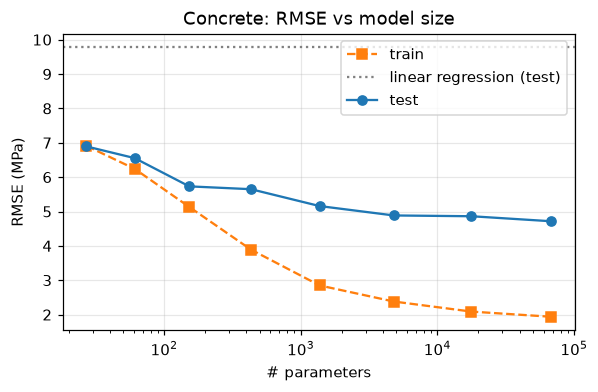

,params,train_rmse,test_rmse,test_rmse_std,test_r2
config,,,,,
m=2,27,6.911,6.894,0.03716,0.8195
m=4,61,6.241,6.553,0.3049,0.837
m=8,153,5.132,5.731,0.395,0.8753
m=16,433,3.891,5.649,0.4338,0.8788
m=32,1377,2.849,5.158,0.103,0.899
m=64,4801,2.381,4.885,0.171,0.9094
m=128,17793,2.088,4.862,0.1139,0.9102
m=256,68353,1.937,4.716,0.3101,0.9156


In [20]:
cwidth, _ = sweep({f"m={w}": dict(hidden=(w, w)) for w in [2, 4, 8, 16, 32, 64, 128, 256]}, cdata, epochs=CEPOCHS)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(cwidth.params, rmse_mpa(cwidth.test_mse), marker="o", label="test")
ax.plot(cwidth.params, rmse_mpa(cwidth.train_mse), "s--", label="train")
ax.axhline(rmse_mpa(ols_mse), color="gray", ls=":", label="linear regression (test)")
ax.set(xscale="log", xlabel="# parameters", ylabel="RMSE (MPa)", title="Concrete: RMSE vs model size")
ax.legend(); plt.show()
with_rmse(cwidth)

**Observations.**
- **Depth:** one hidden layer is clearly worse (5.3 MPa), 2 to 3 hidden layers are best (~4.8-4.9 MPa), and a
  4th layer does not help.
- **Activation:** the ranking is the reverse of the toy problem. ReLU and LeakyReLU are best, then GELU and Tanh,
  and Sigmoid is worst (5.9 MPa). The train errors show why: with the same 300-epoch budget the smooth and
  saturating activations do not fit the training set as well (Tanh 3.0, Sigmoid 5.0 vs ReLU 2.4 MPa), so the
  difference is mostly about how easy they are to optimize.
- **Size:** the test error falls steadily with the number of parameters, from 6.9 MPa (27 parameters, already far better than
  linear regression) to 4.7 MPa (68k parameters). Meanwhile the train error drops to 1.9 MPa, so the gap widens
  but the test error never turns upwards. In this range there is no classic U-shaped bias-variance curve: larger,
  over-parameterized nets still generalize at least as well. The gains above ~5k parameters are small,
  comparable to the seed spread.
- Caveat: as the lab asks, all configurations are compared on the test set. For actually picking a model we would
  use a validation split or cross-validation, and keep the test set for the final number.

## Summary

- An MLP trained with MSE and Adam fits a low-order polynomial down to the noise level within a few dozen epochs.
  Outside the training range a ReLU net extrapolates linearly, so it only learns $f$ where there is data.
- Weight decay is not needed when the model is not overfitting (toy data), and there it only adds bias. On the noisier
  real data there is a train/test gap, but weight decay still did not improve the test error, so it should be tuned rather than assumed to help.
- Capacity needs to match the complexity of the target. A cubic needs only ~100 parameters, but a highly oscillating
  order-21 polynomial needs a deeper/wider network; depth adds capacity more efficiently than width.
- The activation matters mostly through optimization: saturating Sigmoid is consistently the worst, ReLU-type
  activations train fastest, and smooth ones help slightly on smooth 1-D targets.
- On Concrete Compressive Strength, a 2-3 layer MLP roughly halves the error of linear regression (≈ 4.7-4.9 vs
  9.8 MPa RMSE, R² ≈ 0.91 vs 0.64). Bigger models kept generalizing better in the range we tried, despite a growing
  train/test gap.